In [151]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.axes import Axes
from matplotlib.figure import Figure
from scipy import stats
import statsmodels.api as sm
from sklearn.model_selection import cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.linear_model import Ridge

In [152]:
#loading the data
euro_test_df: pd.DataFrame = pd.read_csv("../data/EuroTest.csv")
euro_training_df: pd.DataFrame = pd.read_csv("../data/EuroTraining.csv")
handball_long_df: pd.DataFrame = pd.read_csv("../data/handball_long.csv")
handball_wide_df: pd.DataFrame = pd.read_csv("../data/handball_wide.csv")
tennis_df: pd.DataFrame = pd.read_csv("../data/SlamsData.csv")

# Tennis Data

### Splitting of the data :
**football data:** its already split training and testing datasetes

**tennis data:** following sheet 1 we can use split the data from 2011
to 2017 serve as training data and the data from 2018 to 2024 serve as test data.

In [153]:
#Change to max 3 numbers after the comma
cols_to_round = ["elo", "prob", "age.30"]
tennis_df[cols_to_round] = tennis_df[cols_to_round].round(3)
# Remove the last 2 columns in-place from tennis_df (they are not that useful)
#tennis_df = tennis_df.iloc[:, :-2]

In [154]:
print(tennis_df.columns)

Index(['player.1', 'player.2', 'year', 'tournament', 'surface', 'win',
       'sets.1', 'sets.2', 'rank', 'points', 'elo', 'prob', 'age.30',
       'AvgProb.1', 'AvgProb.2', 'B365.1', 'B365.2'],
      dtype='str')


delete the variable sets because those informations are available only after tha game, for testing it doesnt make sense to know the sets but not the result so they are taken off.

the the CV folds we dont use the usual folds because the data is chronogically bound. We have to respect that and a solution would be the walk-forward validation

In [155]:
columns_to_drop = ["sets.1", "sets.2","B365.1", "B365.2","player.1", "player.2","surface","AvgProb.1", "AvgProb.2","prob"]
#deleted surface because it is redundant with the tournament.
#deleted prob because we dont work with probs
#deleted average because they re redundant
tennis_df = tennis_df.drop(columns=columns_to_drop)

In [156]:
print(tennis_df["year"].value_counts())

year
2023    492
2022    490
2018    487
2021    487
2019    487
2015    481
2024    480
2017    479
2016    479
2012    473
2011    472
2013    472
2014    471
2020    370
Name: count, dtype: int64


In [157]:
# Training data: 2011 to 2021
tennis_train_df: pd.DataFrame = tennis_df[tennis_df["year"].between(2011, 2021)].copy()

# Test data: 2022 to 2024
tennis_test_df: pd.DataFrame = tennis_df[tennis_df["year"].between(2022, 2024)].copy()

generally a 80/20 split for training/testing is a good idea. so by taking the last 3 years as testing data corresponds well. For the rest 11cv folds for each year is actually a good idea.

In [158]:
# Training data
X_train = tennis_train_df.drop(columns=["win", "year"])
y_train = tennis_train_df["win"]

# Test data
X_test = tennis_test_df[X_train.columns]
y_test = tennis_test_df["win"]

# Keep years for cross-validation
years_train = tennis_train_df["year"]

In [159]:
# Select predictors
numeric_cols = X_train.select_dtypes(include="number").columns.tolist()
categorical_cols = ["tournament"]

X_train_model = X_train[numeric_cols + categorical_cols]
X_test_model = X_test[numeric_cols + categorical_cols]

# Preprocessing
preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numeric_cols),
    ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"),
     categorical_cols)
])

# Ridge logistic regression
model = Pipeline([
    ("preprocessor", preprocessor),
    ("logistic", LogisticRegression(max_iter=1000))
])

### This ensures that, during cross-validation:
1. The scaler learns the mean and standard deviation from the current training fold.
2. It transforms that training fold.
3. The logistic regression is trained.
4. The validation fold is transformed using the same scaler, without recalculating its parameters.

In [160]:
#generating the folds:
cv_folds = []

for val_year in range(2015, 2022):

    train_idx = np.where(years_train.to_numpy() < val_year)[0]
    val_idx = np.where(years_train.to_numpy() == val_year)[0]

    cv_folds.append((train_idx, val_idx))

## small pause from the model to check the features

In [161]:
model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('logistic', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](5,)","['tournament','rank','points','elo','age.30']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,5
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwer

In [162]:
# Get feature names after preprocessing
feature_names = model.named_steps["preprocessor"].get_feature_names_out()

# Get logistic regression coefficients
coefficients = model.named_steps["logistic"].coef_[0]

# Create feature importance table
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients,
    "Importance": np.abs(coefficients)
})

# Sort by absolute coefficient
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance.round(4).to_string(index=False))

                    Feature  Coefficient  Importance
                   num__elo       1.5921      1.5921
                num__points       0.1923      0.1923
    cat__tournament_US Open       0.1113      0.1113
                num__age.30       0.0254      0.0254
                  num__rank       0.0221      0.0221
  cat__tournament_Wimbledon       0.0137      0.0137
cat__tournament_French Open       0.0000      0.0000


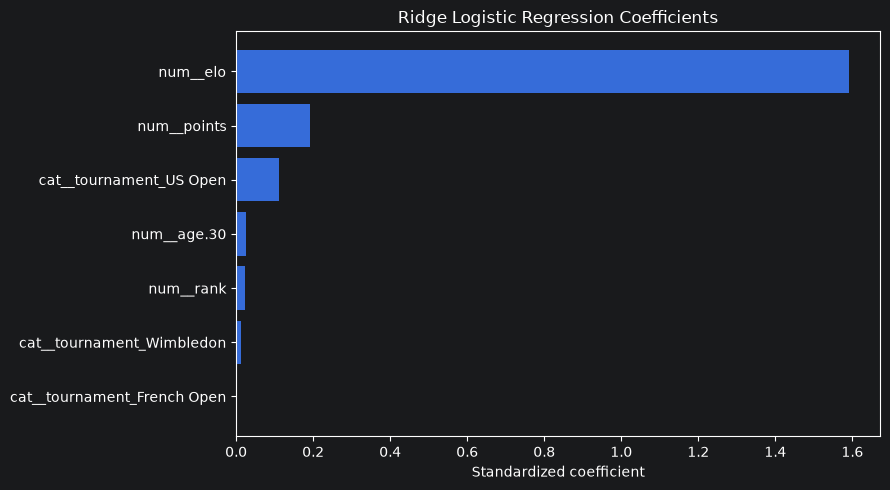

In [163]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.barh(
    feature_importance["Feature"],
    feature_importance["Coefficient"]
)

plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Standardized coefficient")
plt.title("Ridge Logistic Regression Coefficients")
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

In [164]:
scoring = {
    "accuracy": "accuracy",
    "balanced_accuracy": "balanced_accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
    "log_loss": "neg_log_loss",
    "brier": "neg_brier_score"
}

cv_results = cross_validate(
    model,
    X_train_model,
    y_train,
    cv=cv_folds,
    scoring=scoring,
    return_train_score=True
)

In [165]:
results_df = pd.DataFrame({
    "Year": range(2015, 2022),
    "Train Accuracy": cv_results["train_accuracy"],
    "Validation Accuracy": cv_results["test_accuracy"],
    "Balanced Accuracy": cv_results["test_balanced_accuracy"],
    "Precision": cv_results["test_precision"],
    "Recall": cv_results["test_recall"],
    "F1": cv_results["test_f1"],
    "ROC-AUC": cv_results["test_roc_auc"],
    "Log Loss": -cv_results["test_log_loss"],
    "Brier Score": -cv_results["test_brier"]
})

print(results_df.round(4).to_string(index=False))
mean_results = results_df.drop(columns="Year").mean()

print("\nAverage Cross-Validation Performance:")
print(mean_results.round(4))

 Year  Train Accuracy  Validation Accuracy  Balanced Accuracy  Precision  Recall     F1  ROC-AUC  Log Loss  Brier Score
 2015          0.7728               0.7464             0.7462     0.7520  0.7520 0.7520   0.8490    0.4772       0.1589
 2016          0.7640               0.7724             0.7725     0.7782  0.7686 0.7734   0.8572    0.4757       0.1539
 2017          0.7665               0.7599             0.7607     0.7326  0.8043 0.7667   0.8276    0.5210       0.1702
 2018          0.7674               0.7495             0.7495     0.7438  0.7500 0.7469   0.8206    0.5205       0.1731
 2019          0.7638               0.7166             0.7166     0.7177  0.7236 0.7206   0.8113    0.5266       0.1775
 2020          0.7587               0.7216             0.7218     0.7035  0.7609 0.7311   0.7942    0.5464       0.1856
 2021          0.7544               0.7269             0.7261     0.7354  0.7441 0.7397   0.8096    0.5268       0.1778

Average Cross-Validation Performance:
T

           Metric   Test
         Accuracy 0.7264
Balanced Accuracy 0.7259
        Precision 0.7241
           Recall 0.7079
         F1-score 0.7159
          ROC-AUC 0.8139
         Log Loss 0.5234
      Brier Score 0.1760


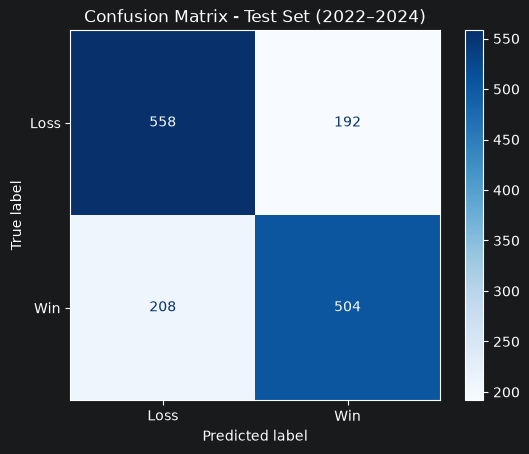

In [166]:
#Fit the model on all the training now and test on the test data that never see
model.fit(X_train_model, y_train)
# Predicted winners (0 or 1)
y_pred = model.predict(X_test_model)

# Predicted probability of winning (class 1)
y_prob = model.predict_proba(X_test_model)[:, 1]
#we need to import these metrics now because in the cross validation it is already implemented in the methods but now we are using them directly
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    log_loss,
    brier_score_loss,
    confusion_matrix
)

test_results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Balanced Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "ROC-AUC",
        "Log Loss",
        "Brier Score"
    ],
    "Test": [
        accuracy_score(y_test, y_pred),
        balanced_accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred),
        recall_score(y_test, y_pred),
        f1_score(y_test, y_pred),
        roc_auc_score(y_test, y_prob),
        log_loss(y_test, y_prob),
        brier_score_loss(y_test, y_prob)
    ]
})

print(test_results.round(4).to_string(index=False))
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["Loss", "Win"],
    cmap="Blues"
)

plt.title("Confusion Matrix - Test Set (2022–2024)")
plt.show()

# UEFA Data

In [167]:
features = [
    "GroupStage",
    "GDP",
    "MarketValue",
    "FifaRank",
    "UefaPoints",
    "CLPlayers"
]

target = "Goals"

# Training data
X_train = euro_training_df[features]
y_train = euro_training_df[target]

# Test data
X_test = euro_test_df[features]
y_test = euro_test_df[target]

In [168]:
model = Pipeline([
    ("scaler", StandardScaler()),
    ("ridge", Ridge())
])

In [169]:
# Find the year column
year_col = next(
    (col for col in euro_training_df.columns
     if col.lower() == "year"),
    None
)

if year_col is None:
    raise ValueError("Please check the name of your year column.")

years_train = euro_training_df[year_col].to_numpy()
unique_years = sorted(np.unique(years_train))

cv_folds = []
validation_years = []

for val_year in unique_years[2:]:
    train_idx = np.where(years_train < val_year)[0]
    val_idx = np.where(years_train == val_year)[0]

    cv_folds.append((train_idx, val_idx))
    validation_years.append(val_year)

print("Validation years:", validation_years)

Validation years: [np.int64(2012), np.int64(2016), np.int64(2020)]


In [170]:
from sklearn.model_selection import cross_validate

scoring = {
    "mae": "neg_mean_absolute_error",
    "mse": "neg_mean_squared_error",
    "r2": "r2",
    "medae": "neg_median_absolute_error"
}

cv_results = cross_validate(
    model,
    X_train,
    y_train,
    cv=cv_folds,
    scoring=scoring,
    return_train_score=True
)

In [171]:
results_df = pd.DataFrame({
    "Year": validation_years,
    "Train MAE": -cv_results["train_mae"],
    "Validation MAE": -cv_results["test_mae"],
    "Validation MSE": -cv_results["test_mse"],
    "Validation RMSE": np.sqrt(-cv_results["test_mse"]),
    "Validation R2": cv_results["test_r2"],
    "Validation Median AE": -cv_results["test_medae"]
})

print(results_df.round(4).to_string(index=False))

 Year  Train MAE  Validation MAE  Validation MSE  Validation RMSE  Validation R2  Validation Median AE
 2012     0.8618          0.8133          1.0493           1.0244         0.1307                0.7233
 2016     0.8356          0.8503          1.0607           1.0299         0.0150                0.7276
 2020     0.8264          0.8672          1.1931           1.0923         0.1568                0.7602


In [172]:
mean_results = results_df.drop(columns="Year").mean()

print("\nAverage Cross-Validation Performance:")
print(mean_results.round(4))


Average Cross-Validation Performance:
Train MAE               0.8413
Validation MAE          0.8436
Validation MSE          1.1010
Validation RMSE         1.0489
Validation R2           0.1008
Validation Median AE    0.7371
dtype: float64


In [173]:
model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('ridge', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](6,)","['GroupStage','GDP','MarketValue','FifaRank','UefaPoints','CLPlayers']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,6
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


In [174]:
coefficients = model.named_steps["ridge"].coef_

feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient": coefficients,
    "Importance": np.abs(coefficients)
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance.round(4).to_string(index=False))

    Feature  Coefficient  Importance
MarketValue       0.2439      0.2439
        GDP       0.1330      0.1330
  CLPlayers       0.1270      0.1270
   FifaRank      -0.0653      0.0653
 UefaPoints      -0.0337      0.0337
 GroupStage      -0.0179      0.0179


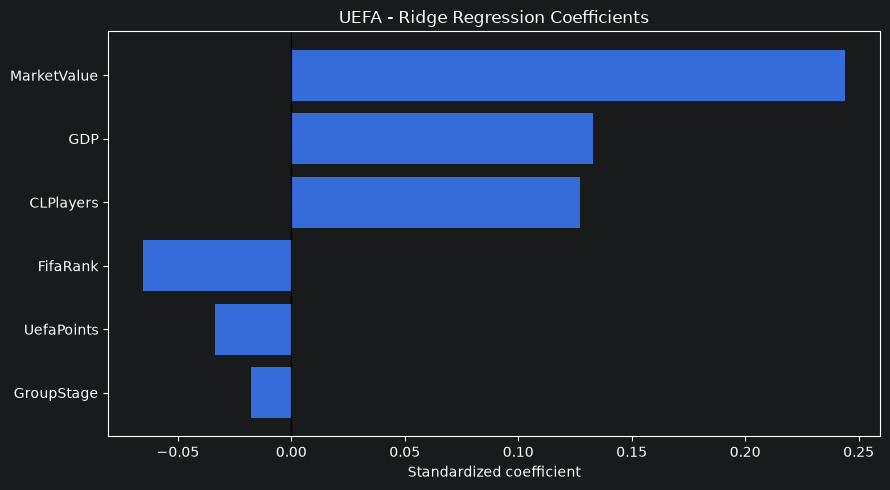

In [175]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.barh(
    feature_importance["Feature"],
    feature_importance["Coefficient"]
)

plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Standardized coefficient")
plt.title("UEFA - Ridge Regression Coefficients")
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

In [176]:
y_pred = model.predict(X_test)

In [177]:
from sklearn.metrics import get_scorer

test_results = {}

for metric_name, scorer_name in scoring.items():
    scorer = get_scorer(scorer_name)

    test_results[metric_name] = scorer(
        model, X_test, y_test
    )

# Convert negative error scores to positive values
test_results["mae"] *= -1
test_results["mse"] *= -1
test_results["medae"] *= -1

# Calculate RMSE
test_results["rmse"] = np.sqrt(test_results["mse"])

print("\nTest Performance:")
print(pd.Series(test_results).round(4))


Test Performance:
mae      0.7408
mse      0.9052
r2       0.1018
medae    0.5799
rmse     0.9514
dtype: float64


In [178]:
comparison = pd.DataFrame({
    "Metric": ["MAE", "MSE", "RMSE", "R2", "Median AE"],

    "Cross-validation": [
        results_df["Validation MAE"].mean(),
        results_df["Validation MSE"].mean(),
        results_df["Validation RMSE"].mean(),
        results_df["Validation R2"].mean(),
        results_df["Validation Median AE"].mean()
    ],

    "Test": [
        test_results["mae"],
        test_results["mse"],
        test_results["rmse"],
        test_results["r2"],
        test_results["medae"]
    ]
})

print(comparison.round(4).to_string(index=False))

   Metric  Cross-validation   Test
      MAE            0.8436 0.7408
      MSE            1.1010 0.9052
     RMSE            1.0489 0.9514
       R2            0.1008 0.1018
Median AE            0.7371 0.5799
